In [17]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
url = "https://archive-api.open-meteo.com/v1/archive"
params = {"latitude": 41.01, "longitude": 28.98,
          "start_date": "2024-01-01", "end_date": "2025-12-31",
          "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum",
          "timezone": "Europe/Istanbul"}
r = requests.get(url, params=params)

In [7]:
data = r.json()
print(data)

{'latitude': 41.01933, 'longitude': 29.015692, 'generationtime_ms': 103.98900508880615, 'utc_offset_seconds': 10800, 'timezone': 'Europe/Istanbul', 'timezone_abbreviation': 'GMT+3', 'elevation': 36.0, 'daily_units': {'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm'}, 'daily': {'time': ['2024-01-01', '2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05', '2024-01-06', '2024-01-07', '2024-01-08', '2024-01-09', '2024-01-10', '2024-01-11', '2024-01-12', '2024-01-13', '2024-01-14', '2024-01-15', '2024-01-16', '2024-01-17', '2024-01-18', '2024-01-19', '2024-01-20', '2024-01-21', '2024-01-22', '2024-01-23', '2024-01-24', '2024-01-25', '2024-01-26', '2024-01-27', '2024-01-28', '2024-01-29', '2024-01-30', '2024-01-31', '2024-02-01', '2024-02-02', '2024-02-03', '2024-02-04', '2024-02-05', '2024-02-06', '2024-02-07', '2024-02-08', '2024-02-09', '2024-02-10', '2024-02-11', '2024-02-12', '2024-02-13', '2024-02-14', '2024-02-15', '2024-02-16', '20

In [10]:
df = pd.DataFrame(data['daily'])

df['time'] = pd.to_datetime(df['time'])

eksik_degerler = df.isnull().sum()

In [11]:
print("--- İlk 5 Satır ---")
print(df.head())

print("\n--- Eksik Değer Kontrolü ---")
print(eksik_degerler)

print("\n--- Veri Tipleri ---")
print(df.dtypes)

--- İlk 5 Satır ---
        time  temperature_2m_max  temperature_2m_min  precipitation_sum
0 2024-01-01                14.5                 7.5                0.0
1 2024-01-02                14.0                 7.1                6.9
2 2024-01-03                14.5                 6.4                2.5
3 2024-01-04                15.3                10.6                1.2
4 2024-01-05                14.0                 8.0                0.6

--- Eksik Değer Kontrolü ---
time                  0
temperature_2m_max    0
temperature_2m_min    0
precipitation_sum     0
dtype: int64

--- Veri Tipleri ---
time                  datetime64[ns]
temperature_2m_max           float64
temperature_2m_min           float64
precipitation_sum            float64
dtype: object


In [13]:
df['temp_mean'] = (df['temperature_2m_max'] + df['temperature_2m_min']) / 2

df.head()

,time,temperature_2m_max,temperature_2m_min,precipitation_sum,temp_mean
0,2024-01-01,14.5,7.5,0.0,11.00
1,2024-01-02,14.0,7.1,6.9,10.55
2,2024-01-03,14.5,6.4,2.5,10.45
3,2024-01-04,15.3,10.6,1.2,12.95
4,2024-01-05,14.0,8.0,0.6,11.00


In [15]:
df['month_year'] = df['time'].dt.to_period('M')

outcome_monthly = df.groupby('month_year').agg(
    avg_temp=('temp_mean', 'mean'),
    total_precip=('precipitation_sum', 'sum')
).reset_index()

outcome_monthly['month_year'] = outcome_monthly['month_year'].astype(str)

print(outcome_monthly)

   month_year   avg_temp  total_precip
0     2024-01   7.345161         112.6
1     2024-02   9.568966          28.7
2     2024-03   9.864516          71.0
3     2024-04  15.726667          67.6
4     2024-05  15.800000          84.1
5     2024-06  24.613333           9.6
6     2024-07  26.309677          36.5
7     2024-08  25.379032          14.0
8     2024-09  22.276667          94.0
9     2024-10  16.764516          10.6
10    2024-11  11.498333          74.6
11    2024-12   9.440323         146.6
12    2025-01   8.375806          86.5
13    2025-02   4.441071          86.7
14    2025-03  12.004839          37.2
15    2025-04  11.711667          49.8
16    2025-05  17.695161          60.4
17    2025-06  23.563333           2.1
18    2025-07  26.912903           0.3
19    2025-08  25.614516           4.6
20    2025-09  21.628333          28.7
21    2025-10  16.045161         141.8
22    2025-11  15.191667          47.4
23    2025-12   9.069355          86.2


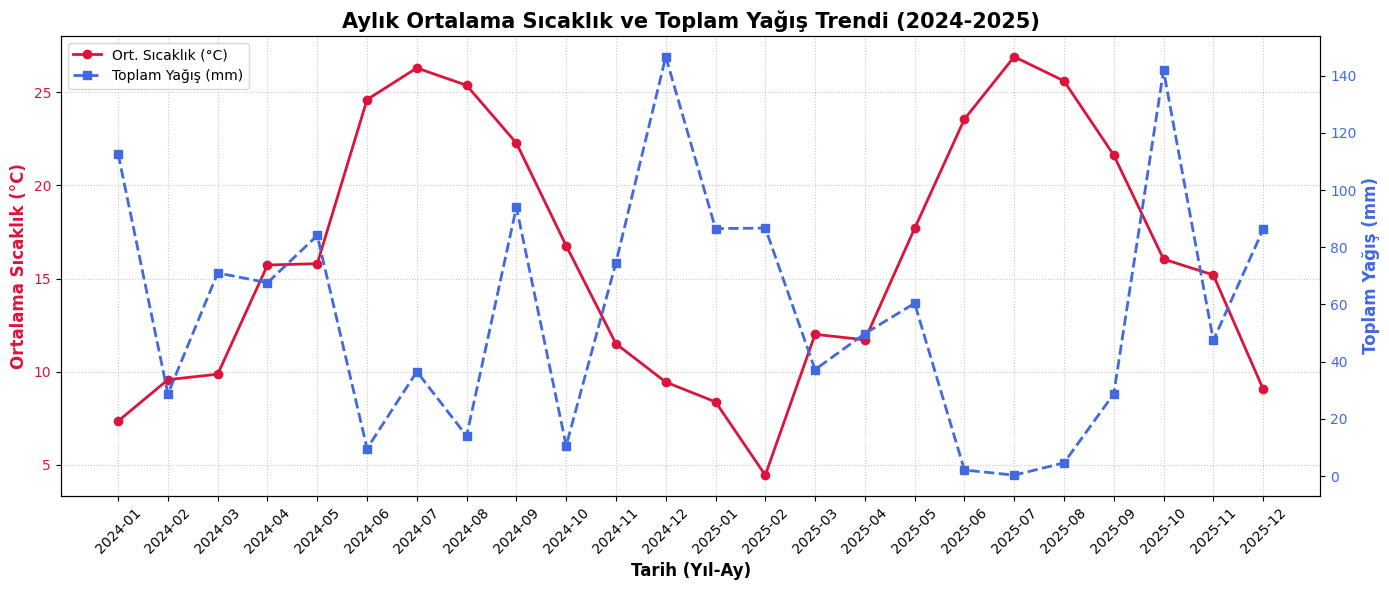

In [18]:
fig, ax1 = plt.subplots(figsize=(14, 6))


ax1.plot(outcome_monthly['month_year'], outcome_monthly['avg_temp'], color='crimson', marker='o', linewidth=2, label='Ort. Sıcaklık (°C)')
ax1.set_xlabel('Tarih (Yıl-Ay)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Ortalama Sıcaklık (°C)', color='crimson', fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='crimson')
ax1.tick_params(axis='x', rotation=45)


ax2 = ax1.twinx()
ax2.plot(outcome_monthly['month_year'], outcome_monthly['total_precip'], color='royalblue', marker='s', linestyle='--', linewidth=2, label='Toplam Yağış (mm)')
ax2.set_ylabel('Toplam Yağış (mm)', color='royalblue', fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='royalblue')


plt.title('Aylık Ortalama Sıcaklık ve Toplam Yağış Trendi (2024-2025)', fontsize=15, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.7)


lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.tight_layout()
plt.show()

In [24]:
from google.colab import auth
auth.authenticate_user()

from google.cloud import bigquery
client = bigquery.Client(project="bigquery-datascientist")


client.load_table_from_dataframe(df, "bigquery-datascientist.dbt_zeynep.raw_weather_istanbul")

LoadJob<project=bigquery-datascientist, location=US, id=9dee82b3-b4f6-45d9-84f1-c08ede358b49>